In [2]:
# 下载 vehicles.mp4 视频文件
from supervision.assets import download_assets, VideoAssets
download_assets(VideoAssets.VEHICLES, 'videos')

[2026-11-11 15:44:32] [INFO] supervision.assets.downloader - Downloading vehicles.mp4 assets


  0%|          | 0/35345757 [00:00<?, ?it/s]

'/Users/justin/Developer/ai-workspace/study-yolo11-in-action/chapter-5-supervision/videos/vehicles.mp4'

In [3]:
def get_video_info(video_path):
    # 提取视频信息
    video_info = sv.VideoInfo.from_video_path(video_path)
    # 通过将总帧数除以帧率并四舍五入到最近一秒来计算视频长度
    # 表示一段时间的长度（时间间隔/持续时间）
    video_length = timedelta(seconds = round(video_info.total_frames / video_info.fps))
    # 打印视频的分辨率、帧率和长度
    # \033[1m → 开始加粗
    # \033[0m → 结束样式（关闭加粗）
    print(f"\033[1mVideo Resolutions: \033[0m ({video_info.width}, {video_info.height})")
    print(f"\033[1mFPS: \033[0m {video_info.fps}")
    print(f"\033[1mLength: \033[0m {video_length}")

In [4]:
# 查看视频信息
from ultralytics import YOLO
import supervision as sv
import cv2
import numpy as np
from datetime import timedelta
import os

# 查看视频信息
video_path = ('./videos/vehicles.mp4')
get_video_info(video_path)

Video Resolutions:  (3840, 2160)
FPS:  25.0
Length:  0:00:22


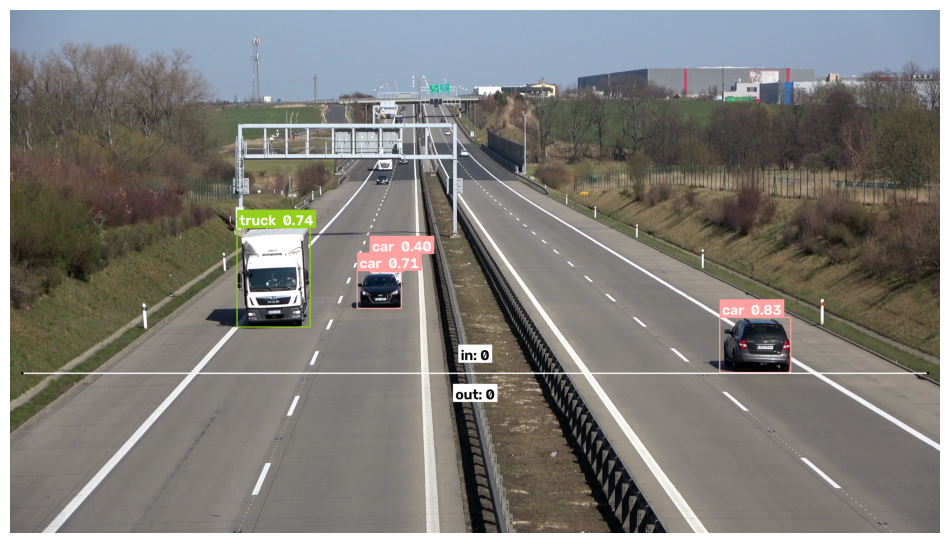

In [7]:
# 定义视频文件路径
video_path = ("./videos/vehicles.mp4")

# 使用视频路径获取视频信息
sv.VideoInfo.from_video_path(video_path)

# 获取视频帧生成器
generator = sv.get_video_frames_generator(video_path)
# 提取第一帧
frame = next(generator)

# 加载 YOLO 模型
model = YOLO("./weights/yolo11n.pt")
# 使用模型对帧进行推理，获取结果
results = model(frame, verbose = False)[0]
# 从推理结果中提取检测信息
detections = sv.Detections.from_ultralytics(results)

# 根据检测结果生成标签
labels = [
    f"{results.names[class_id]} {confidence: 0.2f}" for class_id, confidence in zip(detections.class_id, detections.confidence)
]

# 创建边界框注释器
bounding_box_annotator = sv.BoxAnnotator(thickness = 4)
# 创建标签注释器
label_annotator = sv.LabelAnnotator(text_thickness = 4, text_scale = 2)

# 对帧进行注释
annotated_frame = frame.copy()
annotated_frame = bounding_box_annotator.annotate(
    annotated_frame,
    detections
)
annotated_frame = label_annotator.annotate(
    annotated_frame,
    detections,
    labels
)

# 定义计数线的起点和终点
LINE_START = sv.Point(50, 1500)
LINE_END = sv.Point(3840 - 50, 1500)

# 创建线区域对象
line_zone = sv.LineZone(
    start = LINE_START,
    end = LINE_END
)

# 创建线区域注释器
line_zone_annotator = sv.LineZoneAnnotator(
    thickness = 4,
    text_thickness = 4,
    text_scale = 2
)
# 对帧进行线区域注释
annotated_frame = annotated_frame
annotated_frame = line_zone_annotator.annotate(
    annotated_frame,
    line_counter = line_zone
)
# 显示注释后的帧
sv.plot_image(annotated_frame, (12, 12))

In [18]:
from tqdm import tqdm

# 根据视频路径创建一个视频信息对象
video_info = sv.VideoInfo.from_video_path(video_path)
# 在 callback 外部创建进度条（只创建一次）
pbar = tqdm(total=video_info.total_frames, desc="Processing")

def progress_bar(index): 
    # 更新进度条（按 index 更新，而不是 +1，
    # 因为 process_video 可能是多线程 prefetch，index 不一定连续递增）
    pbar.n = index + 1
    pbar.refresh()

Processing:   0%|                                                                                                                                                         | 0/538 [00:00<?, ?it/s]

In [19]:
def callback(frame: np.ndarray, index: int) -> np.ndarray:
    """
    回调函数，处理每一帧视频。

    参数：
        frame: 当前视频帧。
        index: 当前帧的索引。

    返回：
        处理后的视频帧
    """
    # 使用模型获取当前帧，获取结果
    results = model(frame, verbose = False)[0]

    # 从结果中提取检测信息
    detections = sv.Detections.from_ultralytics(results)
    # 使用字节追踪器更新检测信息
    detections = byte_tracker.update(detections)

    # 生成标签列表，包含每个检测对象的追踪 ID、类别和置信度
    labels = [
        f"#{tracker_id} {model.model.names[class_id]} {confidence: 0.2f}" 
        for confidence, class_id, tracker_id 
        in zip(detections.confidence, detections.class_id, detections.tracker_id)
    ]

    # 复制当前帧，用于绘制注释
    annotated_frame = frame.copy()
    # 使用轨迹注释器在帧上绘制轨迹
    annotated_frame = trace_annotator.annotate(
        scene = annotated_frame,
        detections = detections
    )
    # 使用边界框注释器在帧上绘制边界框
    annotated_frame = bounding_box_annotator.annotate(
        scene = annotated_frame,
        detections = detections
    )
    # 使用标签标注器在帧上绘制标签
    annotated_frame = label_annotator.annotate(
        scene = annotated_frame,
        detections = detections,
        labels = labels
    )
    # 出发线区域检测
    line_zone.trigger(detections)

    # 更新进度条
    progress_bar(index)

    # 返回绘制了线区域的帧
    return line_zone_annotator.annotate(
        annotated_frame,
        line_counter = line_zone
    )

In [20]:
# 处理视频

# 初始化追踪器
from trackers import ByteTrackTracker
byte_tracker = ByteTrackTracker()

# 初始化边界框注释器，设置边界框的厚度
bounding_box_annotator = sv.BoxAnnotator(thickness = 4)
# 初始化标签注释器，设置标签文本的厚度和比例
label_annotator = sv.LabelAnnotator(text_thickness = 4, text_scale = 2)
# 初始化轨迹注释器，设置轨迹的厚度
trace_annotator = sv.TraceAnnotator(thickness = 4)

# 设置目标视频路径
TARGET_VIDEO_PATH = "./output/count-objects-crossing-the-line-result.mp4"

# 处理视频，将源视频路径、目标视频路径和回调函数作为参数
sv.process_video(
    source_path = video_path,
    target_path = TARGET_VIDEO_PATH,
    callback = callback
)


Processing: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 538/538 [00:40<00:00, 13.17it/s]